In [1]:
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", parser="liac-arff")

In [2]:
# create sample size of the first 5000 images 
X_sample, y_sample = mnist.data[:5000], mnist.target[:5000]

In [3]:
# using tsne to reeduce to 2D
tsne = TSNE(n_components=2, init="random", learning_rate="auto", random_state=42)
%time X_reduced = tsne.fit_transform(X_sample)

CPU times: user 1min 39s, sys: 1.67 s, total: 1min 40s
Wall time: 26.4 s


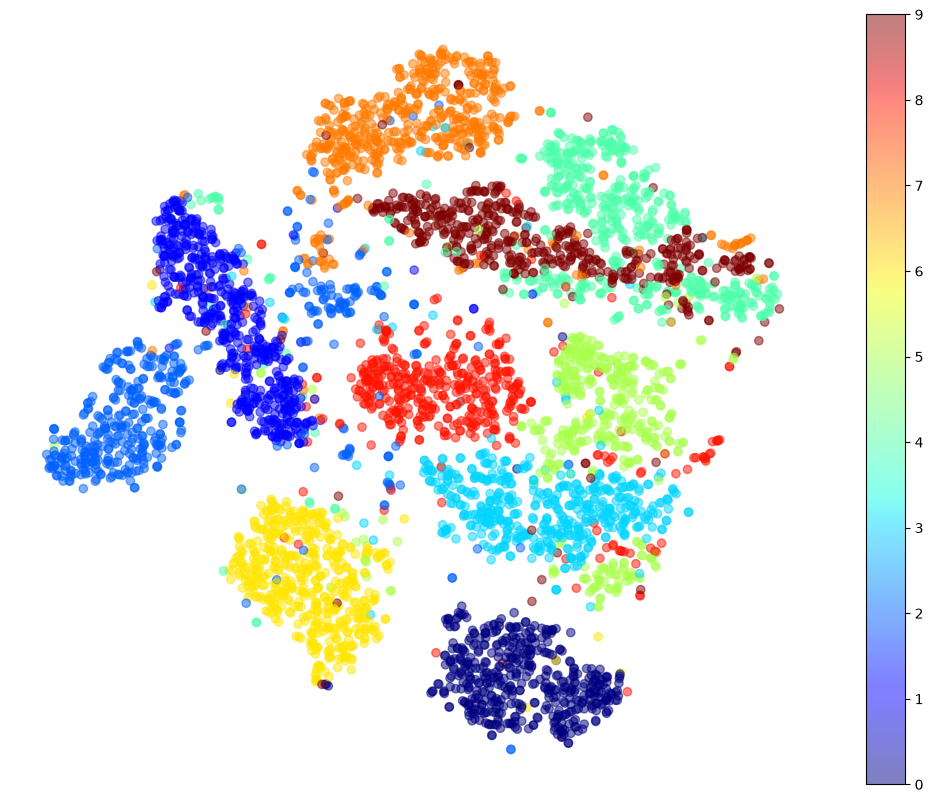

In [4]:
import matplotlib.pyplot as plt 
import numpy as np 

plt.figure(figsize=(13, 10))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1],
            c=y_sample.astype(np.int8), cmap="jet", alpha=0.5)
plt.axis('off')
plt.colorbar()
plt.show()

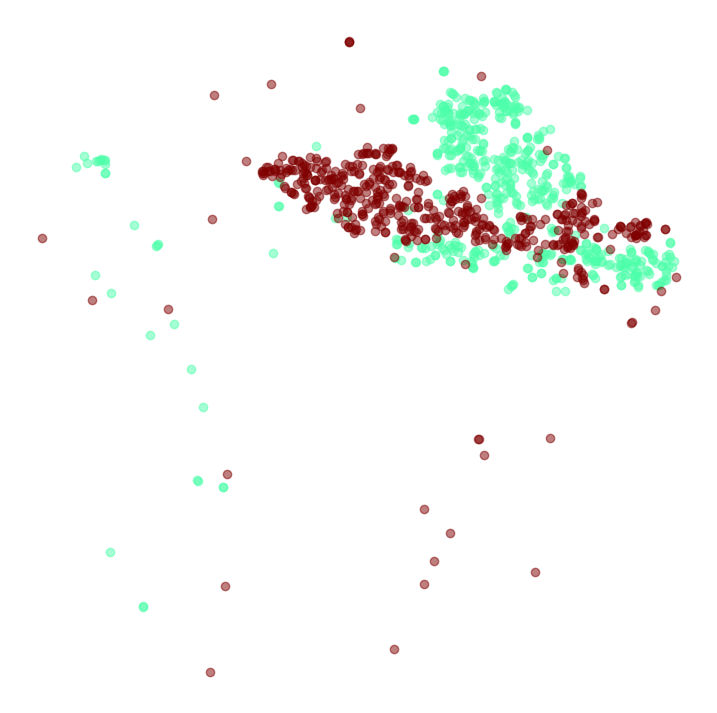

In [5]:
# numbers 4 and 9
plt.figure(figsize=(9, 9))
cmap = plt.cm.jet
for digit in ('4', '9'):
    plt.scatter(X_reduced[y_sample == digit, 0], X_reduced[y_sample == digit, 1],
                c=[cmap(float(digit) / 9)], alpha=0.5)
plt.axis('off')
plt.show()

In [6]:
# Run TSNE on these two digits 
idx = (y_sample == '4') | (y_sample == '9')
X_subset = X_sample[idx]
y_subset = y_sample[idx]

tsne_subset = TSNE(n_components=2, init="random", learning_rate="auto", random_state=42)
X_subset_reduced = tsne_subset.fit_transform(X_subset)


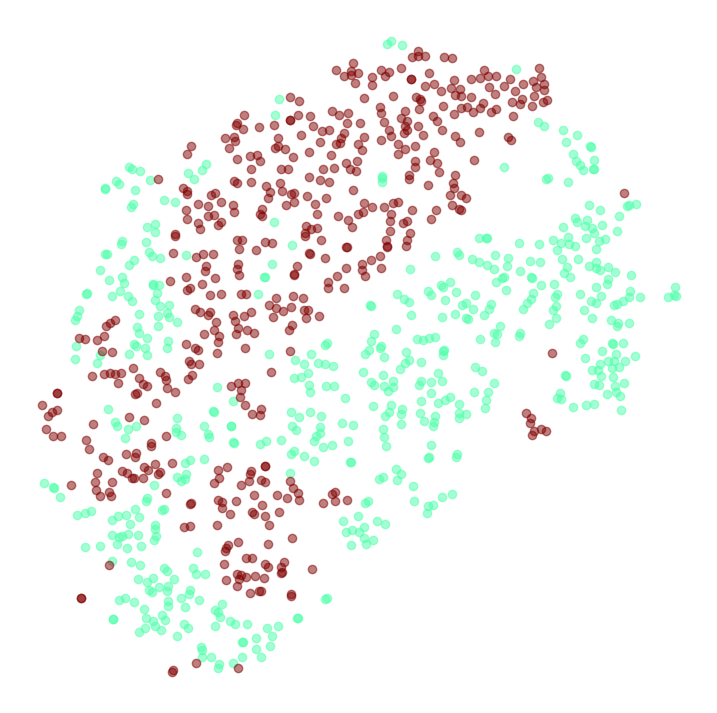

In [7]:
# plot the reduced graph for 4 and 9 
plt.figure(figsize=(9, 9))
for digit in ('4', '9'):
    plt.scatter(X_subset_reduced[y_subset == digit, 0],
                X_subset_reduced[y_subset == digit, 1],
                c=[cmap(float(digit) / 9)], alpha=0.5)
plt.axis('off')
plt.show()

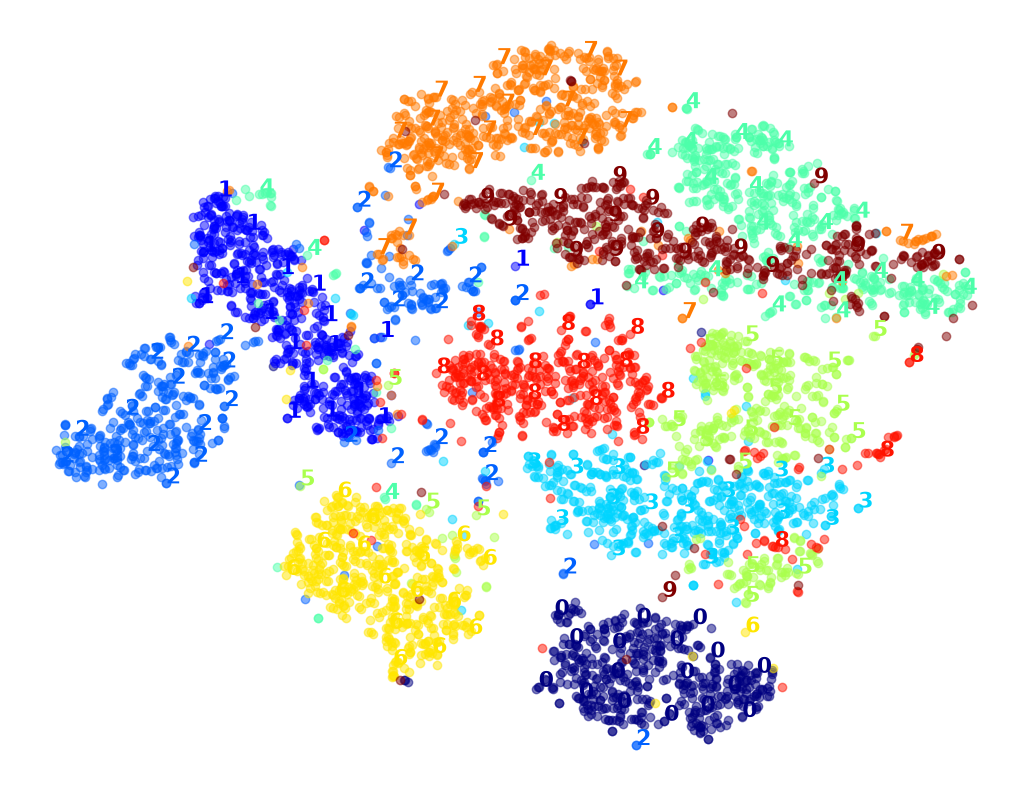

In [8]:
from sklearn.preprocessing import MinMaxScaler
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

# create a scatter plot with coloured digits and minimum distance guranteed between these digits
def plot_digits(X, y, min_distance=0.04, images=None, figsize=(13, 10)):
    X_normalized = MinMaxScaler().fit_transform(X)
    neighbors = np.array([[10., 10.]])
    plt.figure(figsize=figsize)
    cmap = plt.cm.jet
    digits = np.unique(y)
    for digit in digits:
        plt.scatter(X_normalized[y == digit, 0], X_normalized[y == digit, 1],
                    c=[cmap(float(digit) / 9)], alpha=0.5)
    plt.axis("off")
    ax = plt.gca()  
    for index, image_coord in enumerate(X_normalized):
        closest_distance = np.linalg.norm(neighbors - image_coord, axis=1).min()
        if closest_distance > min_distance:
            neighbors = np.r_[neighbors, [image_coord]]
            if images is None:
                plt.text(image_coord[0], image_coord[1], str(int(y[index])),
                         color=cmap(float(y[index]) / 9),
                         fontdict={"weight": "bold", "size": 16})
            else:
                image = images[index].reshape(28, 28)
                imagebox = AnnotationBbox(OffsetImage(image, cmap="binary"),
                                          image_coord)
                ax.add_artist(imagebox)

plot_digits(X_reduced, y_sample)

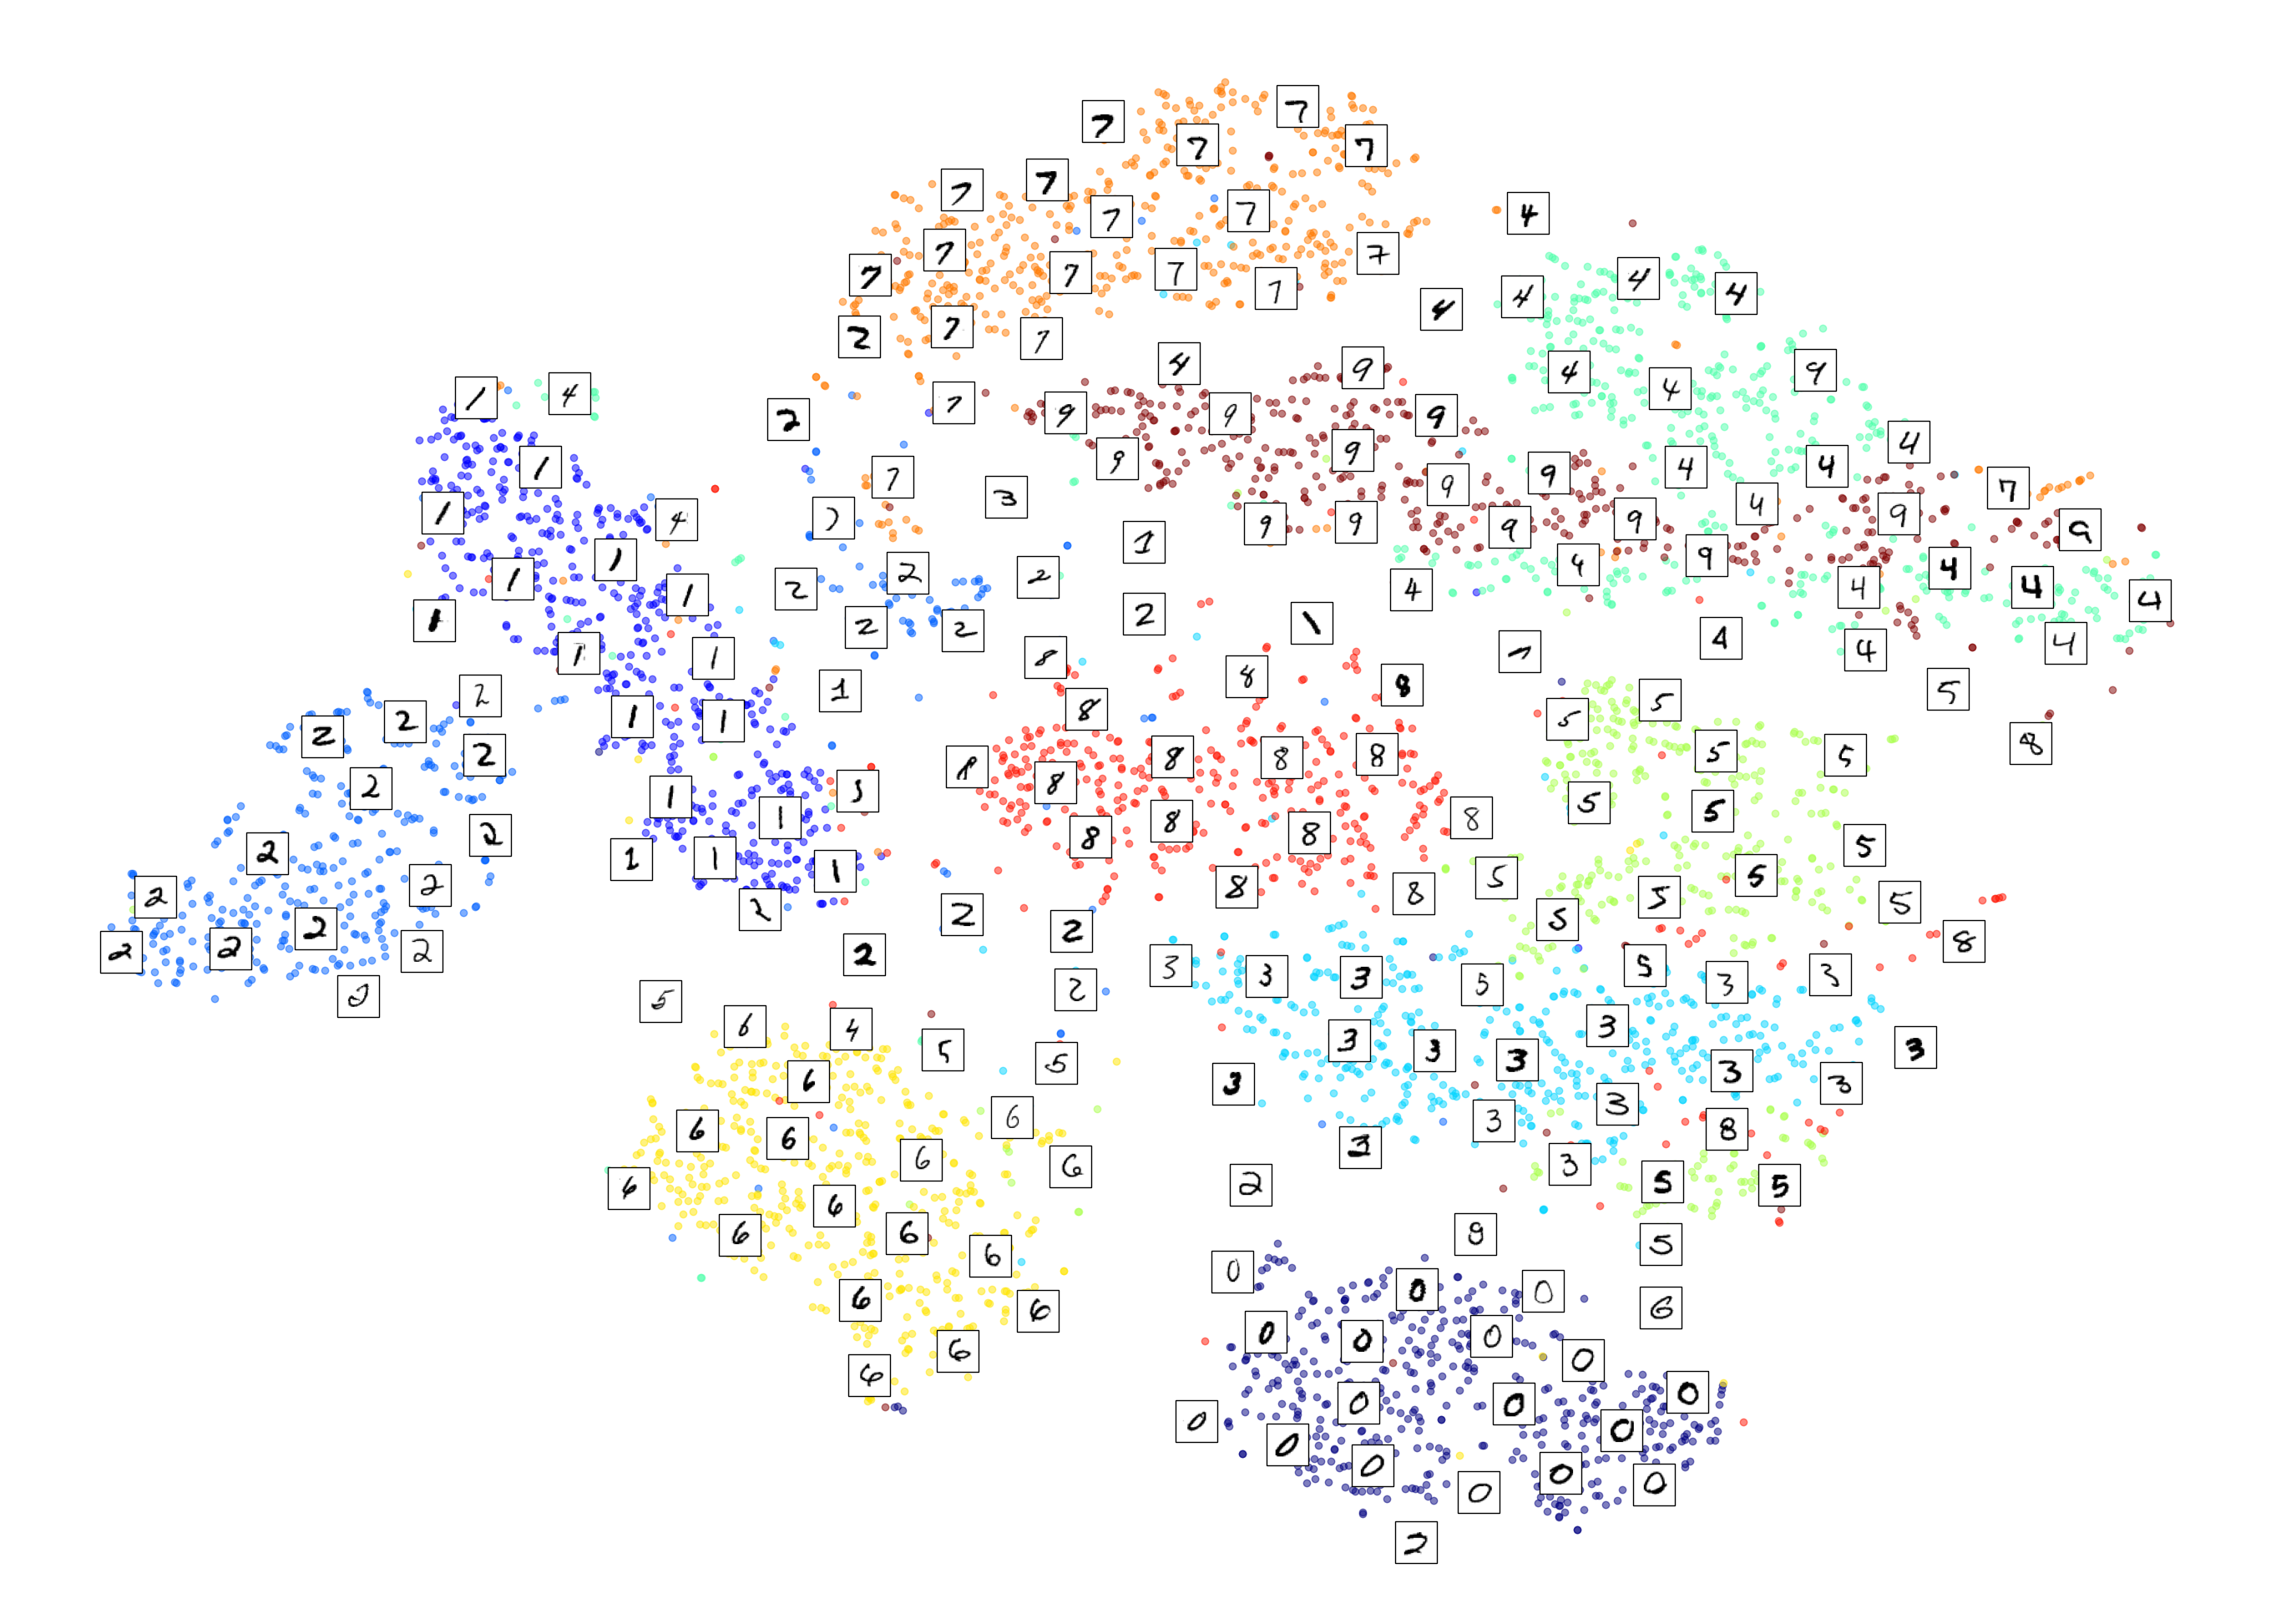

In [9]:
plot_digits(X_reduced, y_sample, images=X_sample.to_numpy(), figsize=(35, 25))

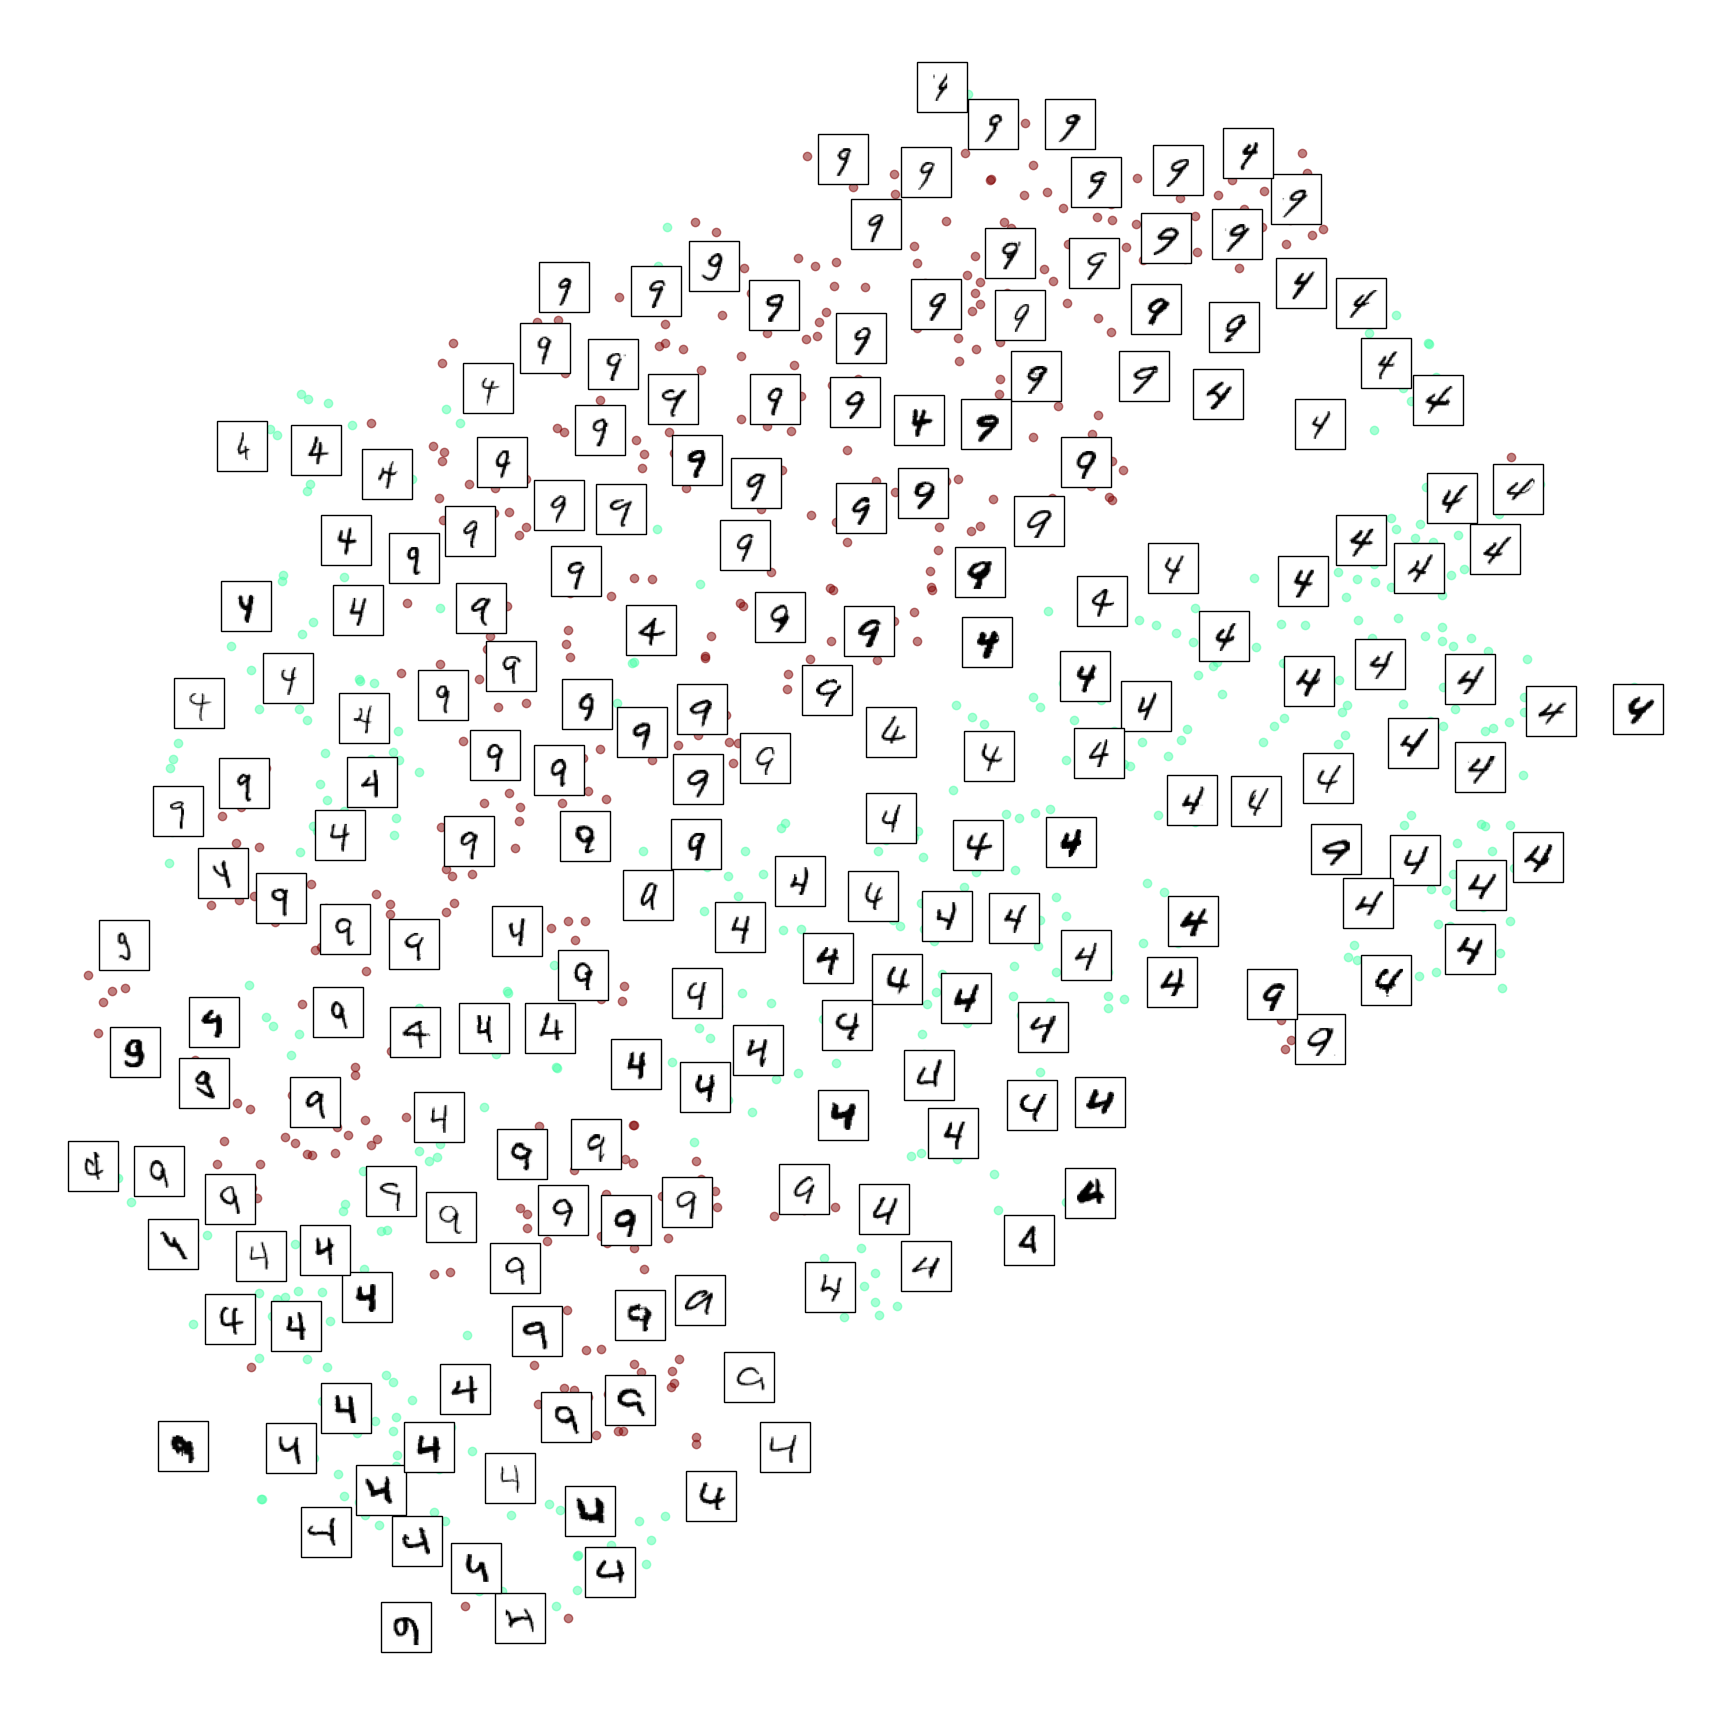

In [10]:
# plot the 4s and 9s using the digit images
plot_digits(X_subset_reduced, y_subset, images=X_subset.to_numpy(), figsize=(22, 22))

CPU times: user 378 ms, sys: 68.7 ms, total: 447 ms
Wall time: 168 ms


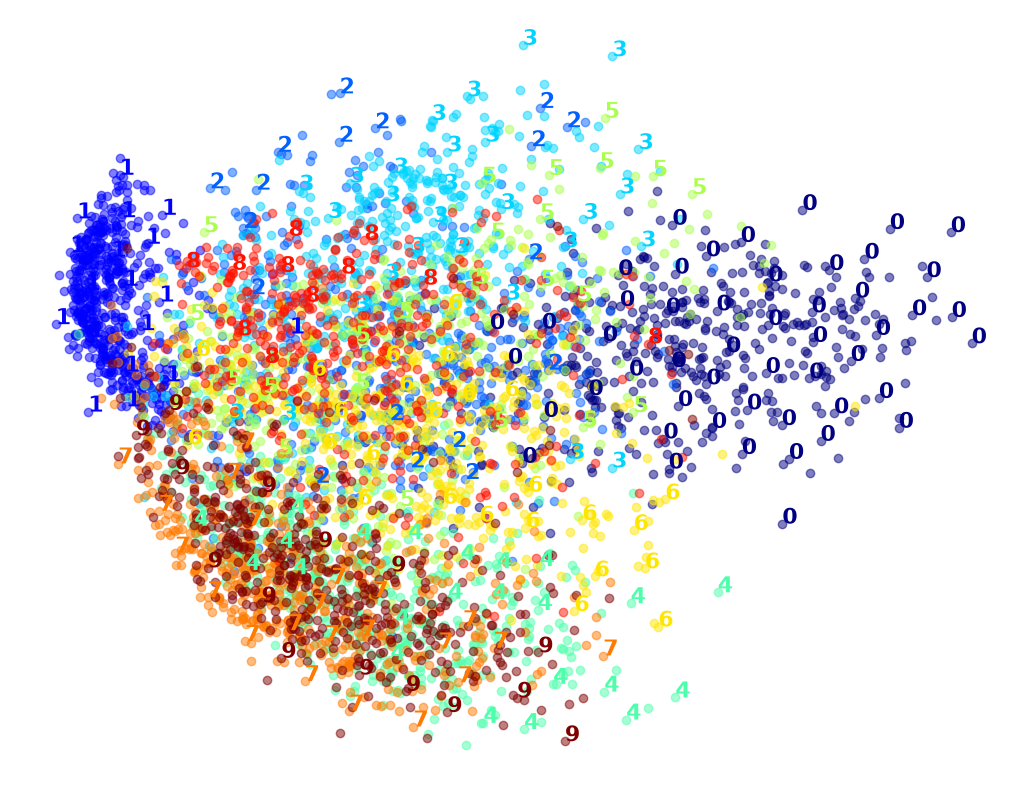

In [11]:
# compare with other dimensionality reduction algorithms
from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.pipeline import make_pipeline

# PCA
pca = PCA(n_components=2, random_state=42)
%time X_pca_reduced = pca.fit_transform(X_sample)
plot_digits(X_pca_reduced, y_sample)
plt.show()

CPU times: user 6.23 s, sys: 674 ms, total: 6.91 s
Wall time: 3.13 s


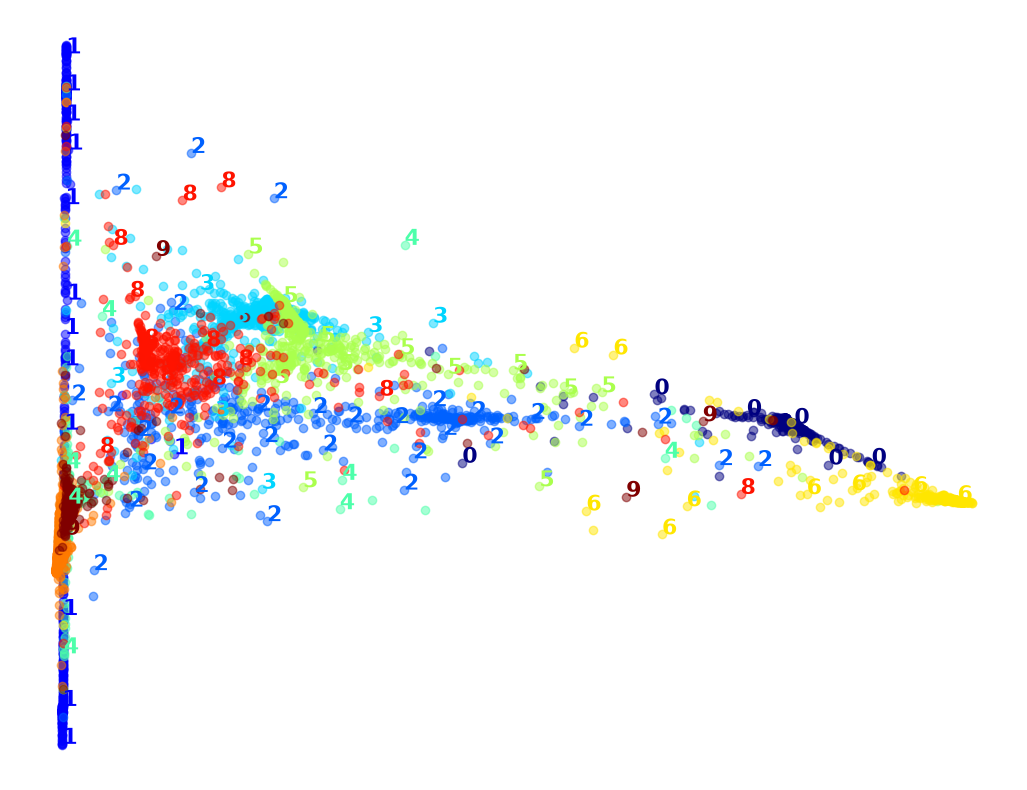

In [12]:
# LLE
lle = LocallyLinearEmbedding(n_components=2, random_state=42)
%time X_lle_reduced = lle.fit_transform(X_sample)
plot_digits(X_lle_reduced, y_sample)
plt.show()

CPU times: user 5.78 s, sys: 953 ms, total: 6.73 s
Wall time: 3.46 s


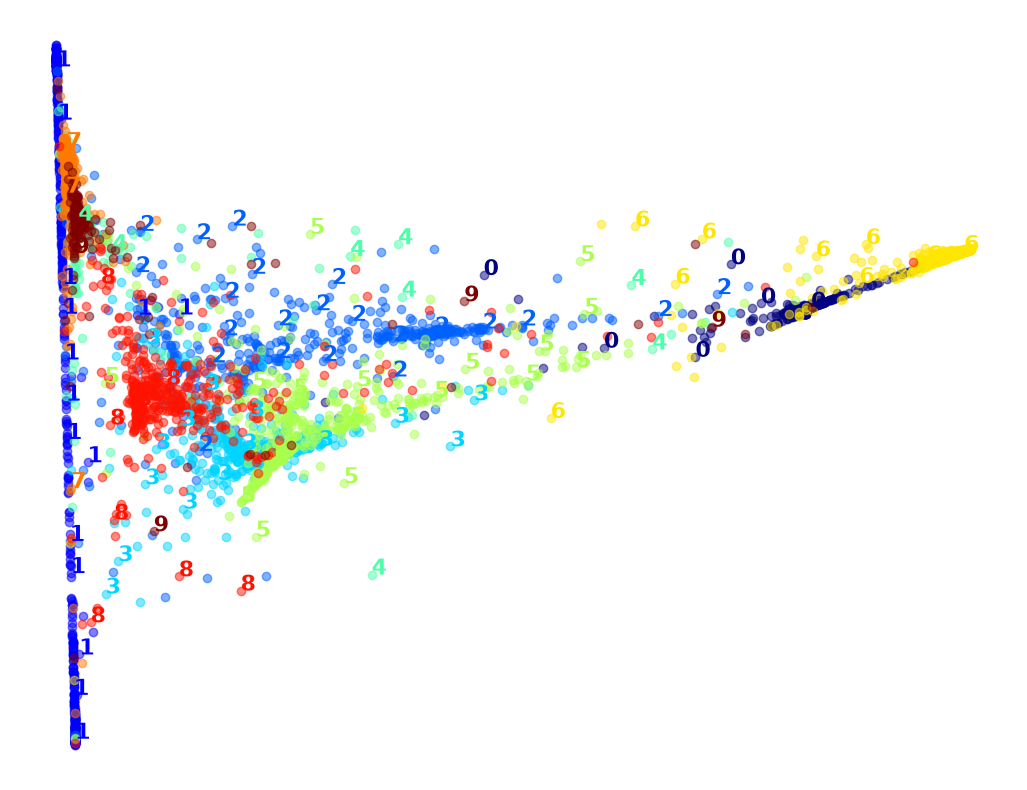

In [13]:
# PCA (95% variance) followed by LLE
pca_lle = make_pipeline(PCA(n_components=0.95),
                        LocallyLinearEmbedding(n_components=2, random_state=42))
%time X_pca_lle_reduced = pca_lle.fit_transform(X_sample)
plot_digits(X_pca_lle_reduced, y_sample)
plt.show()

CPU times: user 2.38 s, sys: 409 ms, total: 2.79 s
Wall time: 1.14 s


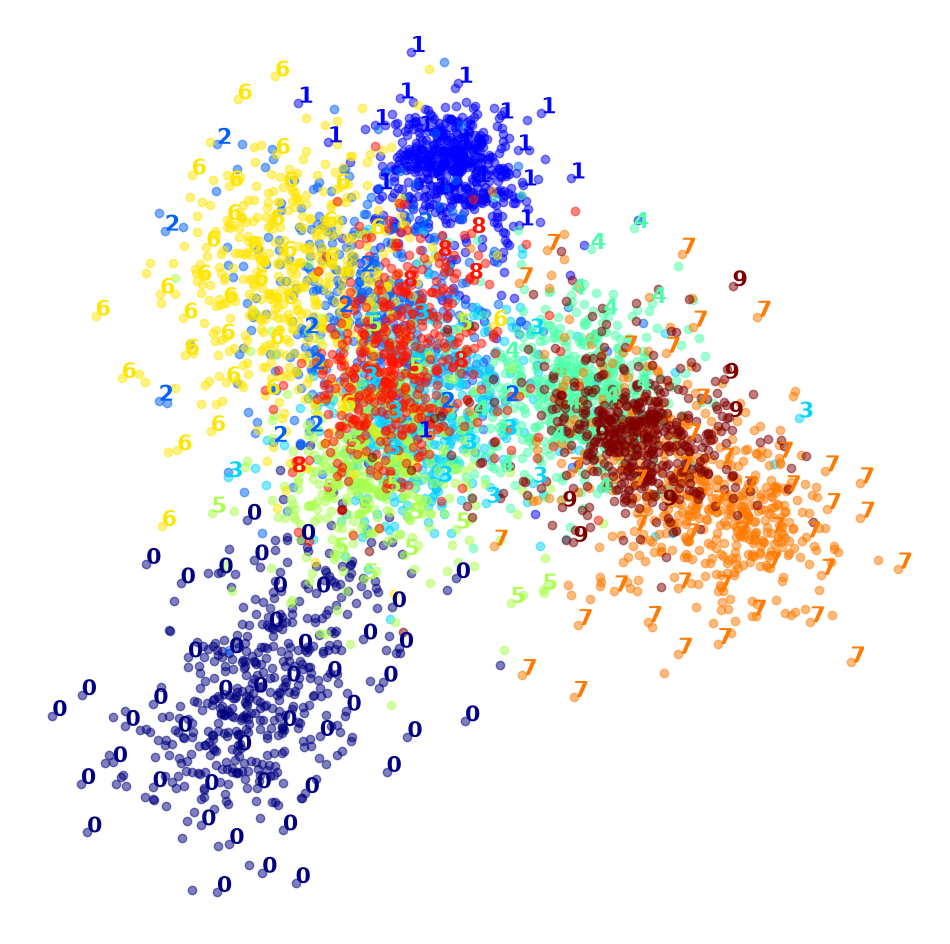

In [14]:
# LDA (uses the labels)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
%time X_lda_reduced = lda.fit_transform(X_sample, y_sample)
plot_digits(X_lda_reduced, y_sample, figsize=(12, 12))
plt.show()